# 2D polydisperse coarse graining of a Janssen pile

In this example, we coarse grain a 2D MFiX simulation of a Janssen pile of spherical particles with several particle sizes (no fluid), resolving the coarse-grained fields per particle phase, and plot the vertical pressure.

The files required for this example can be found in the repository:

- The DEM simulation data files in `examples/data_examples/jannsen_pile/DEM_data/` (time steps 600 to 614)
- The configuration file `config.ini` in `examples/jannsen_pile/`

The coarse graining can also be run from the `compute_CG.ipynb` notebook in `examples/jannsen_pile/`.

## Import packages

In [1]:
from pysammos.utils.config_loader import load_config
from pysammos.coarse_graining import CoarseGraining
from pysammos.data_write.h5.writer import H5XarrayManager

Hello from pysammos
Loading macroscopic_fields package...
Loading data_read package...
Loading particle_phase package...
Loading spatial_weights package...
Loading neighbour_search package...
Loading grid_generation package...
Loading data_handle package...
Loading data_write package...


In [2]:
import numpy as np
import matplotlib.pyplot as plt
import pyvista as pv

In [3]:
from pathlib import Path
import os

# The paths inside config.ini (DEM data, output folder) are relative to the example folder,
# so we work from examples/jannsen_pile/ and read its config.ini.
if "EXAMPLE_DIR" not in globals():          # resolve once, so the cell can be re-run
    EXAMPLE_DIR = (Path.cwd() / "../../examples/jannsen_pile").resolve()
os.chdir(EXAMPLE_DIR)
CONFIG_FILE = EXAMPLE_DIR / "config.ini"
print("Working directory:", Path.cwd())

The history saving thread hit an unexpected error (OperationalError('database is locked')).History will not be written to the database.
Working directory: /exports/csce/datastore/geos/users/s1857688/Coarse_Graining/pysammos/examples/jannsen_pile


## The configuration file

For a description of every section, see the bedload transport example. The file used here is:

In [4]:
print(CONFIG_FILE.read_text())

[paths]
particles_path = ../data_examples/jannsen_pile/DEM_data/DES_FB1_
contacts_path = ../data_examples/jannsen_pile/DEM_data/FC_
output_path = ./PysammosCG/

[timesteps]
t0 = 600
tf = 614
dt = 1
t_pad = 4

[smoothing_function]
type = Lucy

[flags]
partialignore = False

[key_mapping]
Global_ID = Particle_ID
Particle_Velocity = Velocity
Particle_Diameter = Diameter
Particle_Density = Density
Particle_Volume = Volume
Particle_Mass = Mass
Particle_Radius = None
Coordination_Number = None
Particle_i_ID = Particle_ID_1
Particle_j_ID = Particle_ID_2
Force_ij = FORCE_CHAIN_FC
Contact_ij = FORCE_CHAIN_CONTACT_POINT

[DEM_software]
name = mfix
 
[grid_info]
grid_dimension = 2
grid_axes = xy
automatic_grid = False
x_min = -0.23
x_max = 0.23
y_min = 0.001
y_max = 0.1
z_min = None
z_max = None
x_transect = None
y_transect = None
z_transect = 0.0
x_axis_periodic = False
y_axis_periodic = False
z_axis_periodic = False

[fields_to_export]
volume_fraction = True
density_particle = False
density_mix

Compared with the bedload transport example:

- `partialignore = False`: the particle phases are **not** ignored. Pysammos groups the particles into phases by diameter and density, and computes every field for the bulk and for each phase (*polydisperse* mode). The output files are named `CG_Lucy_Polydisperse*`.
- `x_min = -0.23` ... `y_max = 0.1`, with `z_transect = 0.0`: a 2D grid in the `xy` plane, with no periodic boundaries.
- `coordination_number = True`: it is not in the MFiX output, so Pysammos calculates it from the contacts.
- Time steps 600 to 614 are coarse grained (`t0`, `tf`, `dt`).

## Initialise the `CoarseGraining` class

`load_config` returns the arguments of `CoarseGraining` as a dictionary, so they can be passed directly with `**`. You can also give each argument explicitly, as shown in the bedload transport example.

In [5]:
cfg = load_config(CONFIG_FILE)
CG = CoarseGraining(**cfg)

Output path created: ./PysammosCG/


## Run the coarse graining

The whole workflow can be run with a single command:

```python
CG.run()
```

Here we run it step by step instead, to show what each step does.

### 1. Load the size-relevant particle data for the first time step

In [6]:
Bounds_t0, Diameter_t0, Density_t0, Mass_t0, GlobalID_t0 = CG.data_sampling()

Sampling data for the first time step to obtain particle properties and bounds ... 
XML-based PolyData detected.


### 2. Calculate the particle size statistics

In [7]:
CG.get_particle_size_statistics(Diameter_t0, Mass_t0)
print(">> Particle size statistics: ")
print("       d43: ", CG.d43)
print("       dmax: ", CG.dmax)
print("       d50: ", CG.d50)
print("       d32: ", CG.d32)
print("       drms: ", CG.drms)

>> Particle size statistics: 
       d43:  0.005067612399400709
       dmax:  0.005999645
       d50:  0.005061278
       d32:  0.005012527178597786
       drms:  0.004928972383396669


### 3. Get the phases

With `partialignore = False`, the particles are clustered into phases by diameter and density (here with up to 8 clusters). The figure shows the clustering.

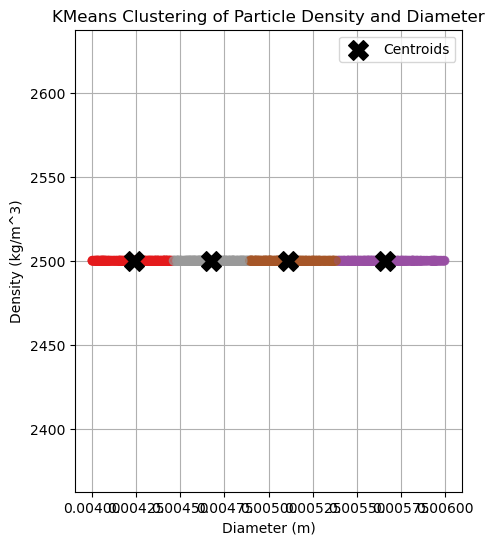

>> Phases: 
       Diameters:  [0.00423757 0.00566325 0.00510815 0.00467504]
       Densities:  [2500. 2500. 2500. 2500.]


In [8]:
CG.get_particle_phases(Diameter_t0, Density_t0, GlobalID_t0, 8)
print(">> Phases: ")
print("       Diameters: ", CG.phases[:,0])
print("       Densities: ", CG.phases[:,1])

### 4. Calculate the coarse-graining resolution

The argument is the reference diameter; a larger value gives a wider kernel (larger `w` and cutoff `c`).

In [9]:
CG.set_resolution(CG.d43)
print(">> Coarse Graining resolution: ")
print("       c:", CG.c)
print("       w:", CG.w)

>> Coarse Graining resolution: 
       c: 0.007601418599101063
       w: 0.0038007092995505313


### 5. Generate the coarse-graining grid

In [10]:
CG.generate_grid()
print(">> Grid: ")
print("       Grid Points: ", CG.GridPoints.shape, "First Point: ", CG.GridPoints[0])
print("       Nodes: ", CG.Nodes)
print("       Spacing: ", CG.Spacing)

Generating Grid with Customised Grid Ranges
Customised grid bounds: x = [-0.23, 0.23], y = [0.001, 0.1], z = [None, None], x_transect = None, y_transect = None, z_transect = 0.0
>> Grid: 
       Grid Points:  (3444, 3) First Point:  [-0.23   0.001  0.   ]
       Nodes:  [123  28   1]
       Spacing:  [0.00377049 0.00366667]


### 6. Calculate the coarse-grained fields

In [11]:
CG.fields_in_time()

 
-------------------- Calculating Coarse Grained Fields --------------------
 
---> Time step 0: time 0600 ................................................
Loading data ... 
  Particle data loaded
  Repeated pairs in contact data:  0
  Contact data loaded and mapped
  Coordination number not provided. Calculating it.
... data loaded
Matching particles to grid points ...
... particles assigned to grid nodes
Computing weights ...
  Using Lucy kernel with cutoff 0.007601418599101063 and search sampling factor 1000
... weights computed
Computing Coarse Graining fields...
  volume fraction done
  mixture density done
  momentum density done
  velocity done
  velocity gradient done
  kinetic tensor done
  contact tensor done
  Z done
  frabric tensor done
  total stress done
  pressure done
  granular temp done
  mu done
... fields computed
Writing results for timestep 600...


/exports/csce/datastore/geos/users/s1857688/Coarse_Graining/pysammos/pysammos/macroscopic_fields/gridded/derived_fields.py:216: RuntimeWarning: divide by zero encountered in divide
  out[f"frictional_coefficient_{s_name}_P{p_name}"] = tau / out[f"pressure_{p_name}"]


  File successfully updated to ./PysammosCG/CG_Lucy_Polydisperse.h5
File successfully written to ./PysammosCG/CG_Lucy_Polydisperse_0600.vtkhdf
... results written
  File successfully updated to ./PysammosCG/CG_GranularTemperature_slices.h5
  File successfully written to ./PysammosCG/CG_GranularTemperature_slices.h5
>> time step 0 took 9.809610605239868 to run.
  
---> Time step 1: time 0601 ................................................
Loading data ... 
  Particle data loaded
  Repeated pairs in contact data:  0
  Contact data loaded and mapped
  Coordination number not provided. Calculating it.
... data loaded
Matching particles to grid points ...
... particles assigned to grid nodes
Computing weights ...
  Using Lucy kernel with cutoff 0.007601418599101063 and search sampling factor 1000
... weights computed
Computing Coarse Graining fields...
  volume fraction done
  mixture density done
  momentum density done
  velocity done
  velocity gradient done
  kinetic tensor done
  cont

/exports/csce/datastore/geos/users/s1857688/Coarse_Graining/pysammos/pysammos/macroscopic_fields/gridded/derived_fields.py:216: RuntimeWarning: divide by zero encountered in divide
  out[f"frictional_coefficient_{s_name}_P{p_name}"] = tau / out[f"pressure_{p_name}"]


  File successfully updated to ./PysammosCG/CG_Lucy_Polydisperse.h5
File successfully written to ./PysammosCG/CG_Lucy_Polydisperse_0601.vtkhdf
... results written
  File successfully updated to ./PysammosCG/CG_GranularTemperature_slices.h5
  File successfully written to ./PysammosCG/CG_GranularTemperature_slices.h5
>> time step 1 took 0.6379914283752441 to run.
  
---> Time step 2: time 0602 ................................................
Loading data ... 
  Particle data loaded
  Repeated pairs in contact data:  0
  Contact data loaded and mapped
  Coordination number not provided. Calculating it.
... data loaded
Matching particles to grid points ...
... particles assigned to grid nodes
Computing weights ...
  Using Lucy kernel with cutoff 0.007601418599101063 and search sampling factor 1000
... weights computed
Computing Coarse Graining fields...
  volume fraction done
  mixture density done
  momentum density done
  velocity done
  velocity gradient done
  kinetic tensor done
  con

## Plotting the results

The coarse-grained fields are saved in `examples/jannsen_pile/PysammosCG/`.

### 1. Read the coarse-grained data

In [12]:
manager = H5XarrayManager("./PysammosCG/CG_Lucy_Polydisperse.h5")
janssen_CG = manager.h5_to_xarray()

Processing key: coordination_number
Processing key: density_mixture
Processing key: fabric_tensor
Processing key: frictional_coefficient_01_Pxy
Processing key: frictional_coefficient_01_Pxyz
Processing key: frictional_coefficient_01_Py
Processing key: frictional_coefficient_Dxy_Pxy
Processing key: frictional_coefficient_Dxy_Pxyz
Processing key: frictional_coefficient_Dxy_Py
Processing key: frictional_coefficient_Dxyz_Pxy
Processing key: frictional_coefficient_Dxyz_Pxyz
Processing key: frictional_coefficient_Dxyz_Py
Processing key: granular_temperature_x
Processing key: granular_temperature_xyz
Processing key: granular_temperature_y
Processing key: granular_temperature_z
Processing key: phases
Processing key: positions
Processing key: pressure_x
Processing key: pressure_xy
Processing key: pressure_xyz
Processing key: pressure_y
Processing key: pressure_z
Processing key: time
Processing key: total_stress_tensor_xy_dev
Processing key: total_stress_tensor_xy_dev_mag
Processing key: total_s

In polydisperse mode the fields have a `phase` dimension: index 0 is the bulk, followed by one entry per phase, in the order of `CG.phases`.

In [13]:
janssen_CG.phase

<xarray.DataArray 'phase' (phase: 5)> Size: 700B
array(['Bulk', 'Phase_[4.2375745e-03 2.5000000e+03]',
       'Phase_[5.6632482e-03 2.5000000e+03]',
       'Phase_[5.108148e-03 2.500000e+03]',
       'Phase_[4.6750368e-03 2.5000000e+03]'], dtype='<U35')
Coordinates:
  * phase    (phase) <U35 700B 'Bulk' ... 'Phase_[4.6750368e-03 2.5000000e+03]'

### 2. Vertical pressure

We plot the vertical normal stress `pressure_y`, averaged over the time steps: (a) the bulk value on the grid, with the DEM particles of the last time step on top, and (b) its vertical profile along the centre of the pile, for the bulk and for each phase, compared with the hydrostatic pressure $\rho g h$.

In [14]:
def vertical_profile(x, y, var, x_center, tolerance, n_bins=30):
    """Bin-average var along y, for the grid points within tolerance of x = x_center."""
    mask = np.abs(x - x_center) < tolerance
    y_sel, var_sel = y[mask], var[mask]
    y_bins = np.linspace(y_sel.min(), y_sel.max(), n_bins + 1)
    bin_idx = np.digitize(y_sel, y_bins)
    y_centers, var_means = [], []
    for i in range(1, n_bins + 1):
        m = bin_idx == i
        if np.any(m):
            y_centers.append(y_sel[m].mean())
            var_means.append(var_sel[m].mean())
    return np.array(var_means), np.array(y_centers)

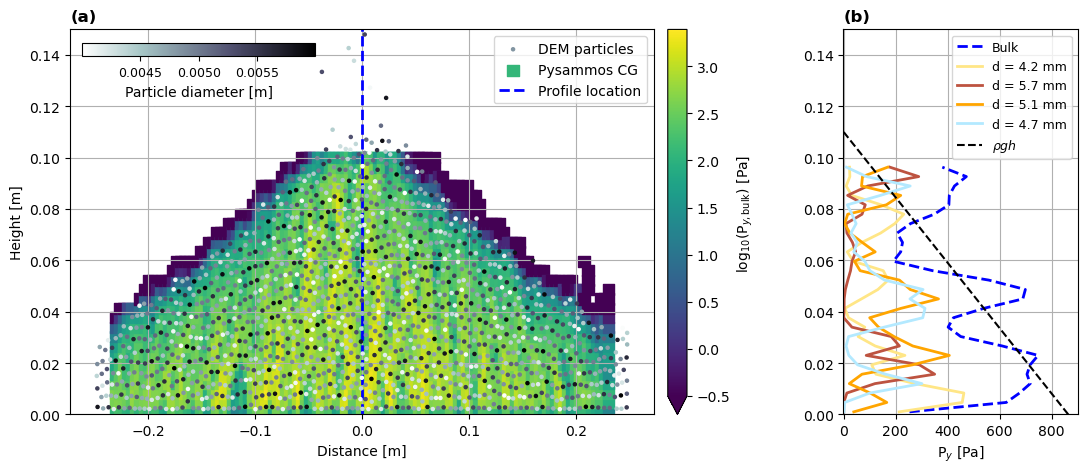

In [15]:
# coarse-grained data: time average of pressure_y, shape (points, phases)
x = np.asarray(janssen_CG.positions[:, 0])
y = np.asarray(janssen_CG.positions[:, 1])
p_y = np.asarray(janssen_CG.pressure_y.values).mean(axis=0)
p_y_bulk = p_y[:, 0]

# DEM particles of the last time step
last_step = int(janssen_CG.time[-1])
janssen_DEM = pv.read(f"../data_examples/jannsen_pile/DEM_data/DES_FB1_{last_step:04d}.vtp")

fig, ax = plt.subplots(1, 2, figsize=(13, 5), gridspec_kw={"width_ratios": [3, 1]})

# (a) DEM particles and bulk pressure on the grid
particles = ax[0].scatter(janssen_DEM.points[:, 0], janssen_DEM.points[:, 1], s=5,
                          c=janssen_DEM["Diameter"], cmap="bone_r", zorder=3, label="DEM particles")
cax = ax[0].inset_axes([0.02, 0.93, 0.4, 0.035])
cbar = fig.colorbar(particles, cax=cax, orientation="horizontal")
cbar.set_label("Particle diameter [m]", fontsize=10)
cbar.ax.tick_params(labelsize=9)

log_p = np.log10(np.where(p_y_bulk > 0, p_y_bulk, np.nan))   # empty nodes have p = 0
sc = ax[0].scatter(x, y, s=65, c=log_p, cmap="viridis", marker="s", zorder=1,
                   vmin=-0.5, label="Pysammos CG")
cbar_sc = fig.colorbar(sc, ax=ax[0], pad=0.02, extend="min")
cbar_sc.set_label(r"log$_{10}$(P$_{y,\mathrm{bulk}}$) [Pa]")

x_center, tolerance = 0.0, 0.004
ax[0].axvline(x=x_center, color="blue", ls="--", lw=2, label="Profile location")

# (b) vertical profiles along x = x_center: bulk and phases
bulk_profile, y_profile = vertical_profile(x, y, p_y_bulk, x_center, tolerance)
ax[1].plot(bulk_profile, y_profile, "--", color="blue", lw=2, label="Bulk")
phase_colors = ["#FFE686", "#BD5340", "orange", "#B3E9FF", "#6A8D73", "#8E7DBE", "#C9A227", "#555555"]
for p, d_phase in enumerate(CG.phases[:, 0], start=1):
    profile, _ = vertical_profile(x, y, p_y[:, p], x_center, tolerance)
    ax[1].plot(profile, y_profile, "-", lw=2, color=phase_colors[(p - 1) % len(phase_colors)],
               label=f"d = {d_phase * 1e3:.1f} mm")

# hydrostatic reference: bulk density and fill height set by hand for this pile
rho_bulk, fill_height, g = 800.0, 0.11, 9.81
h = np.linspace(0, fill_height)
ax[1].plot(rho_bulk * g * (fill_height - h), h, "k--", label=r"$\rho g h$")

for a, label in zip(ax, ["(a)", "(b)"]):
    a.set_title(label, loc="left", fontweight="bold")
    a.set_ylim(0, 0.15)
    a.grid()
ax[0].legend(fontsize=10, loc="upper right")
ax[1].legend(fontsize=9, loc="upper right")
ax[0].set_xlabel("Distance [m]")
ax[0].set_ylabel("Height [m]")
ax[1].set_xlabel(r"P$_y$ [Pa]")
ax[1].set_xlim(-1, 900)
plt.subplots_adjust(wspace=0.15)
plt.show()